In [32]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import precision_score, recall_score



df = pd.read_csv("course_lead_scoring_2026.csv")

print("Initial shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nMissing values per column before fill:")
print(df.isnull().sum())

Initial shape: (5000, 9)
Columns: ['lead_source', 'industry', 'employment_status', 'location', 'annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']

Missing values per column before fill:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [33]:
# Identify numerical vs categorical columns
categorical_features = df.select_dtypes(include=['object', 'category', 'str', 'string']).columns
numerical_features = df.select_dtypes(include=['number']).columns

df[cat_cols] = df[cat_cols].fillna('NA')
df[num_cols] = df[num_cols].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [34]:
numerical_vars = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
y_train = df_train['converted']

auc_scores = {}
for var in numerical_vars:
    scores = df_train[var]
    auc = roc_auc_score(y_train, scores)
    
    # Invert variable if AUC < 0.5
    if auc < 0.5:
        auc = roc_auc_score(y_train, -scores)
        
    auc_scores[var] = auc

print("ROC AUC Feature Importance:")
for var, score in auc_scores.items():
    print(f" - {var}: {score:.4f}")

ROC AUC Feature Importance:
 - lead_score: 0.7882
 - number_of_courses_viewed: 0.7230
 - interaction_count: 0.7649
 - annual_income: 0.6082


In [35]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values

# Define feature columns (all columns except the target variable)
features = [col for col in df.columns if col != 'converted']

# 4. Apply One-Hot Encoding using DictVectorizer
train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# 5. Question 2: Train Logistic Regression model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

# Predict probabilities and calculate ROC AUC on validation set
y_pred_val = model.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_pred_val)

print(f"Validation AUC: {val_auc:.4f}")
print(f"Validation AUC (rounded to 3 digits): {round(val_auc, 3)}")

Validation AUC: 0.7318
Validation AUC (rounded to 3 digits): 0.732


Intersection Threshold: 0.63
Precision: 0.7328, Recall: 0.7253


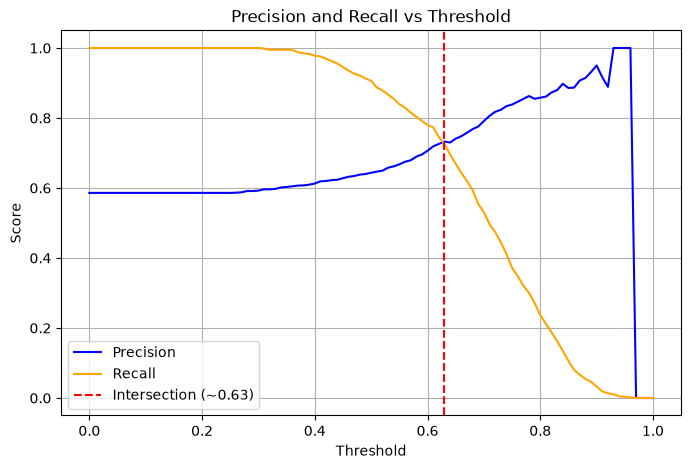

In [36]:
# Evaluate precision and recall across thresholds from 0.0 to 1.0 with step 0.01
thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []
abs_diffs = []

for t in thresholds:
    y_pred = (y_pred_val >= t)
    p = precision_score(y_val, y_pred, zero_division=0)
    r = recall_score(y_val, y_pred, zero_division=0)
    
    precisions.append(p)
    recalls.append(r)
    
    # Ignore thresholds where both are 0
    if p == 0 and r == 0:
        abs_diffs.append(float('inf'))
    else:
        abs_diffs.append(abs(p - r))

# Find threshold with the smallest absolute difference
min_diff_idx = np.argmin(abs_diffs)
intersect_threshold = thresholds[min_diff_idx]

print(f"Intersection Threshold: {intersect_threshold:.2f}")
print(f"Precision: {precisions[min_diff_idx]:.4f}, Recall: {recalls[min_diff_idx]:.4f}")

# Plot precision and recall curves
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label='Precision', color='blue')
plt.plot(thresholds, recalls, label='Recall', color='orange')
plt.axvline(x=intersect_threshold, color='red', linestyle='--', label=f'Intersection (~{intersect_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)
plt.savefig('precision_recall_plot.png')
plt.show()

Maximal F1 Score: 0.7576 at threshold 0.41


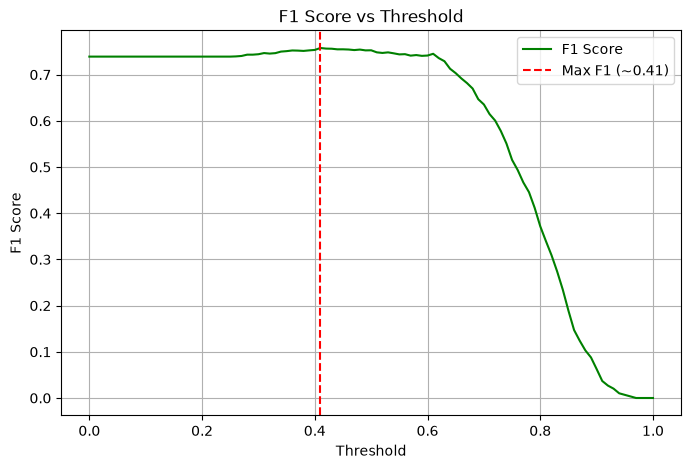

In [37]:

# Evaluate F1 score across thresholds from 0.0 to 1.0 with step 0.01
thresholds = np.arange(0.0, 1.01, 0.01)
f1_scores = []

for t in thresholds:
    y_pred = (y_pred_val >= t)
    p = precision_score(y_val, y_pred, zero_division=0)
    r = recall_score(y_val, y_pred, zero_division=0)
    
    if p + r == 0:
        f1 = 0.0
    else:
        f1 = 2 * (p * r) / (p + r)
    f1_scores.append(f1)

# Find maximum F1 score and corresponding threshold
max_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[max_f1_idx]
max_f1 = f1_scores[max_f1_idx]

print(f"Maximal F1 Score: {max_f1:.4f} at threshold {best_threshold:.2f}")

# Plot F1 score across thresholds
plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_scores, label='F1 Score', color='green')
plt.axvline(x=best_threshold, color='red', linestyle='--', label=f'Max F1 (~{best_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold')
plt.legend()
plt.grid(True)
plt.savefig('f1_score_plot.png')
plt.show()

In [38]:
features = [col for col in df_full_train.columns if col != 'converted']

# 3. Question 5: 5-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=1)
auc_scores = []

for train_idx, val_idx in kf.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]
    
    y_train_fold = df_train_fold['converted'].values
    y_val_fold = df_val_fold['converted'].values
    
    train_dicts = df_train_fold[features].to_dict(orient='records')
    val_dicts = df_val_fold[features].to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    X_train_fold = dv.fit_transform(train_dicts)
    X_val_fold = dv.transform(val_dicts)
    
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train_fold, y_train_fold)
    
    y_pred_fold = model.predict_proba(X_val_fold)[:, 1]
    auc = roc_auc_score(y_val_fold, y_pred_fold)
    auc_scores.append(auc)

# Compute standard deviation across folds
std_auc = np.std(auc_scores)

print(f"AUC scores: {[round(s, 4) for s in auc_scores]}")
print(f"Standard Deviation: {std_auc:.4f}")
print(f"Rounded Standard Deviation: {round(std_auc, 3)}")

AUC scores: [0.7306, 0.7296, 0.7363, 0.7412, 0.7209]
Standard Deviation: 0.0069
Rounded Standard Deviation: 0.007


In [39]:
c_values = [0.000001, 0.001, 1]
kf = KFold(n_splits=5, shuffle=True, random_state=1)

results = []

for C in c_values:
    auc_scores = []
    
    for train_idx, val_idx in kf.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]
        
        y_train_fold = df_train_fold['converted'].values
        y_val_fold = df_val_fold['converted'].values
        
        train_dicts = df_train_fold[features].to_dict(orient='records')
        val_dicts = df_val_fold[features].to_dict(orient='records')
        
        dv = DictVectorizer(sparse=False)
        X_train_fold = dv.fit_transform(train_dicts)
        X_val_fold = dv.transform(val_dicts)
        
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train_fold, y_train_fold)
        
        y_pred_fold = model.predict_proba(X_val_fold)[:, 1]
        auc = roc_auc_score(y_val_fold, y_pred_fold)
        auc_scores.append(auc)
        
    mean_auc = np.mean(auc_scores)
    std_auc = np.std(auc_scores)
    
    results.append({
        'C': C,
        'Mean AUC': round(mean_auc, 3),
        'Std AUC': round(std_auc, 3)
    })

results_df = pd.DataFrame(results)
print(results_df)

          C  Mean AUC  Std AUC
0  0.000001     0.617    0.019
1  0.001000     0.749    0.010
2  1.000000     0.732    0.007
